# 01 — FortyGuard API & MCP Exploration

This notebook summarizes the **Phase 1–3 REST and MCP evaluation** using only local, sanitized JSON artifacts saved under `data/raw/` (**0 API credits spent** when running this notebook).

It covers:
1. Account & sanitization verification
2. All 6 REST `POST` endpoints: async polling behavior and latency
3. `/v1/satellite` granularity behavior (`100m` vs `20m` vs `80m`)
4. Negative validation & error-handling behavior
5. MCP tool inventory (11 tools) and REST-vs-MCP interoperability
6. Credit economics (`heatmap` vs `satellite`) that motivated Phase 4's design

In [8]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

RAW_DIR = Path("../data/raw") if Path("../data/raw").exists() else Path("data/raw")
print("Using RAW_DIR:", RAW_DIR.resolve())

Using RAW_DIR: C:\Users\Kamiye\Desktop\urban-heat model\data\raw


## 1. Account & Secret-Redaction Check
`src/client.py` automatically redacts sensitive fields (`api_key`, `subscription_id`, `download_link`, etc.) before writing JSONs to disk.

In [9]:
acct = json.loads((RAW_DIR / "account_usage.json").read_text(encoding="utf-8"))
print("api_key:", acct.get("api_key"))
print("subscription_id:", acct.get("subscription_id"))
print("Plan:", acct.get("plan_details", {}).get("plan_type"), "| Cycle:", acct.get("plan_details", {}).get("cycle_type"))
print("Initial credit limit:", acct.get("credit_summary", {}).get("total_available_credits"))

api_key: [REDACTED]
subscription_id: [REDACTED]
Plan: Premium | Cycle: One-Time
Initial credit limit: 1000000


## 2. REST Endpoint Smoke Tests (Async Lifecycle & Latency)
Every `POST` endpoint on `https://api.fortyguard.com` returned an asynchronous `activity_id` that we polled via `GET /v1/status/{activity_id}`.

In [10]:
smoke_files = [
    "env_params_la_20240715_result.json",
    "heatmap_la_20240715.json",
    "satellite_la_20240715.json",
    "satellite_la_20240715_ft3.json",
    "satellite_la_20240715_g20.json",
    "satellite_la_20240715_g80.json",
    "routing_la_20240715.json",
    "streetview_la_20240715.json",
    "heat_intelligence_la_20240715.json",
]

rows = []
for fname in smoke_files:
    fpath = RAW_DIR / fname
    if not fpath.exists():
        continue
    d = json.loads(fpath.read_text(encoding="utf-8"))
    poll = d.get("poll") or {}
    sub = d.get("submit") or {}
    rows.append({
        "file": fname,
        "label": d.get("label", fname),
        "submit_http": sub.get("status_code"),
        "submit_s": round(sub.get("latency_s", 0.0), 2),
        "poll_status": poll.get("final_status"),
        "poll_attempts": poll.get("attempts"),
        "poll_elapsed_s": round(poll.get("total_elapsed_s", 0.0), 2),
    })

smoke_df = pd.DataFrame(rows)
smoke_df

,file,label,submit_http,submit_s,poll_status,poll_attempts,poll_elapsed_s
0,env_params_la_20240715_result.json,env_params_la_20240715_result.json,None,0.0,NaN,NaN,0.00
1,heatmap_la_20240715.json,heatmap_la_20240715.json,None,0.0,Completed,6.0,32.47
2,satellite_la_20240715.json,satellite_la_20240715.json,None,0.0,NaN,NaN,0.00
3,satellite_la_20240715_ft3.json,satellite_la_20240715_ft3.json,None,0.0,Failed,20.0,123.55
4,satellite_la_20240715_g20.json,satellite_la_20240715_g20.json,None,0.0,Completed,5.0,26.37
5,satellite_la_20240715_g80.json,satellite_la_20240715_g80.json,None,0.0,Completed,2.0,9.77
6,routing_la_20240715.json,routing_la_20240715.json,None,0.0,Completed,5.0,30.14
7,streetview_la_20240715.json,streetview_la_20240715.json,None,0.0,Completed,2.0,14.82
8,heat_intelligence_la_20240715.json,heat_intelligence_la_20240715.json,None,0.0,Completed,26.0,157.31


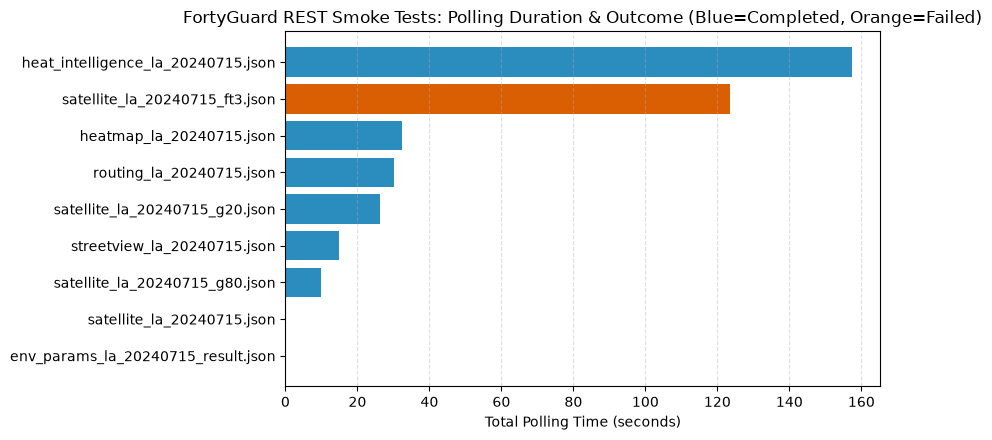

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.5))
plot_df = smoke_df.sort_values("poll_elapsed_s")
colors = ["#d95f02" if s == "Failed" else "#2b8cbe" for s in plot_df["poll_status"]]
ax.barh(plot_df["file"], plot_df["poll_elapsed_s"], color=colors)
ax.set_xlabel("Total Polling Time (seconds)")
ax.set_title("FortyGuard REST Smoke Tests: Polling Duration & Outcome (Blue=Completed, Orange=Failed)")
ax.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

## 3. `/v1/satellite` Granularity Behavior (`20m` vs `80m`)
In Downtown LA (`34.0522, -118.2437`), `granularity=100` failed with no diagnostic message (`0` credits), `granularity=20` zoomed onto a tiny `80x80` roof crop (`76.59% others`, `0.83% sea`), while `granularity=80` produced a clean `350x350` urban segmentation.

g20 dimensions: {'width': 80, 'height': 80} | classes: {'earth, ground': 8.61, 'sea': 0.83, 'sand': 13.97, 'others': 76.59}
g80 dimensions: {'width': 350, 'height': 350} | classes: {'building': 22.22, 'tree': 6.22, 'road, route': 63.04, 'grass': 2.19, 'earth, ground': 6.33, 'others': 0.01}


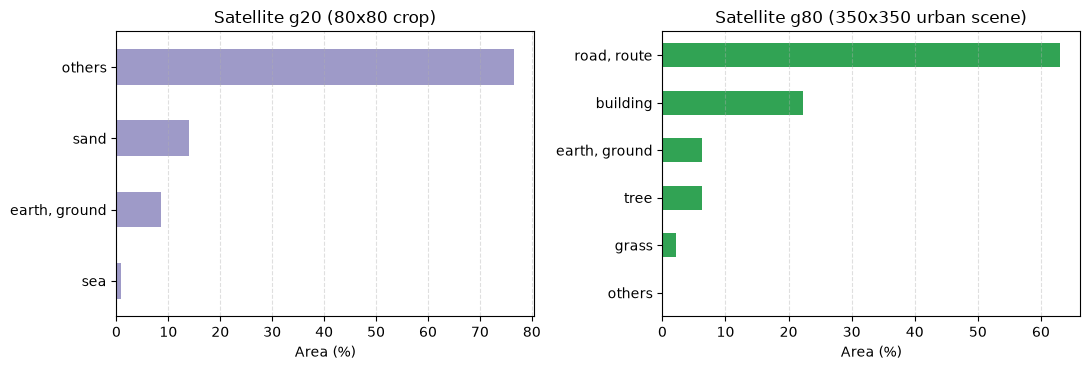

In [12]:
g20 = json.loads((RAW_DIR / "satellite_la_20240715_g20.json").read_text(encoding="utf-8"))
g80 = json.loads((RAW_DIR / "satellite_la_20240715_g80.json").read_text(encoding="utf-8"))

seg20 = g20["poll"]["final_body"]["data"]["result"]["segmentation"]
seg80 = g80["poll"]["final_body"]["data"]["result"]["segmentation"]

print("g20 dimensions:", seg20["image_dimensions"], "| classes:", seg20["segments"])
print("g80 dimensions:", seg80["image_dimensions"], "| classes:", seg80["segments"])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
pd.Series(seg20["segments"]).sort_values().plot(kind="barh", ax=axes[0], color="#9e9ac8", title="Satellite g20 (80x80 crop)")
pd.Series(seg80["segments"]).sort_values().plot(kind="barh", ax=axes[1], color="#31a354", title="Satellite g80 (350x350 urban scene)")
for ax in axes:
    ax.set_xlabel("Area (%)")
    ax.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

## 4. Negative Validation & Error Handling (`0` credits)
Testing malformed requests revealed clean `422`/`400` validation for missing fields and unclosed polygons, but an **unhandled `HTTP 500`** on malformed date/enum values (`2024-99-99`, `filter_type=99`).

In [13]:
neg = json.loads((RAW_DIR / "negative_validation_tests.json").read_text(encoding="utf-8"))
neg_rows = []
items = neg.get("tests", neg) if isinstance(neg, dict) else neg
if isinstance(items, dict):
    for k, v in items.items():
        neg_rows.append({"test": k, "status_code": v.get("status_code"), "latency_s": v.get("latency_s")})
elif isinstance(items, list):
    for v in items:
        neg_rows.append({"test": v.get("name", v.get("test")), "status_code": v.get("status_code"), "latency_s": v.get("latency_s")})
pd.DataFrame(neg_rows)

,test,status_code,latency_s
0,missing_required_fields_env_params,422,2.633
1,out_of_range_coords_env_params,422,0.804
2,malformed_date_and_enum_env_params,500,1.980
3,unclosed_polygon_heatmap,400,1.390


## 5. MCP Interface (11 Tools) & Cross-Interface Compatibility
Unlike REST (where all 6 POSTs require async polling), MCP exposes 11 tools over Streamable HTTP (`https://tos-mcp.app.fortyguard.com/mcp`), wrapping `env_params`, `satellite`, and `streetview` synchronously while keeping `heatmap` async (`heatmap` + `heatmap_read`). Notably, MCP `heatmap_read` can read a REST-created `activity_id` directly.

In [14]:
mcp_tools = json.loads((RAW_DIR / "mcp_tools.json").read_text(encoding="utf-8"))
tools_list = mcp_tools.get("tools_list", {}).get("result", {}).get("tools", [])
print(f"Discovered {len(tools_list)} MCP tools:")
pd.DataFrame([{"name": t["name"], "description": (t.get("description") or "")[:110]} for t in tools_list])

Discovered 11 MCP tools:


,name,description
0,credit_balance,Read your available Enterprise API credits; fr...
1,env_params,Point-level environmental conditions for a sin...
2,heatmap,Submit a standalone temperature or analytic he...
3,heatmap_read,Read bounded persisted statistics from an exis...
4,monitoring,Recurring temperature monitors of a heatmap: l...
5,report,Submit a heat-intelligence report for a point ...
6,report_read,Read an existing completed Heat Intelligence r...
7,satellite,Segment a satellite image for a point into lan...
8,streetview,Segment street-view imagery for a point into v...
9,temperature_routing,Submit temperature-aware route generation betw...


## 6. Credit Economics: Why Phase 4 Used `heatmap` + Open GIS
* `POST /v1/satellite` costs **`14,400` credits per single point**.
* `POST /v1/heatmap` costs **`4,220` credits per ~0.8 km² grid** and returns **~72–81 labeled `100m x 100m` tiles** (~55 credits per tile — **~260x cheaper per labeled observation**).

That cost ratio drove our Phase 4 design: collect **2,507 tiles across 36 LA neighborhoods** via `heatmap` (`~147,700` total heatmap credits) and enrich every tile with free OpenStreetMap & elevation data (`0` credits).

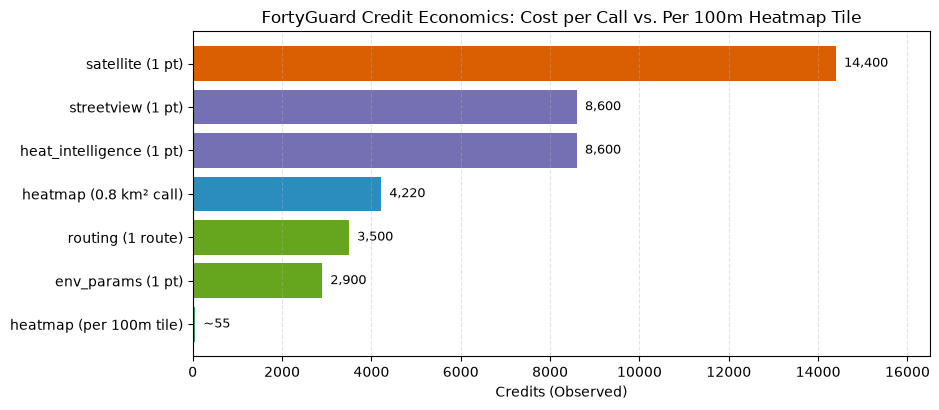

In [15]:
endpoints = ["satellite (1 pt)", "streetview (1 pt)", "heat_intelligence (1 pt)", "heatmap (0.8 km² call)", "routing (1 route)", "env_params (1 pt)", "heatmap (per 100m tile)"]
credits = [14400, 8600, 8600, 4220, 3500, 2900, 55.2]
colors = ["#d95f02", "#7570b3", "#7570b3", "#2b8cbe", "#66a61e", "#66a61e", "#31a354"]

fig, ax = plt.subplots(figsize=(9.5, 4.2))
bars = ax.barh(endpoints[::-1], credits[::-1], color=colors[::-1])
ax.set_xlabel("Credits (Observed)")
ax.set_title("FortyGuard Credit Economics: Cost per Call vs. Per 100m Heatmap Tile")
ax.grid(axis="x", linestyle="--", alpha=0.35)
for bar, val in zip(bars, credits[::-1]):
    ax.text(val + 180, bar.get_y() + bar.get_height() / 2, f"{val:,.0f}" if val >= 100 else f"~{val:.0f}", va="center", fontsize=9)
ax.set_xlim(0, 16500)
plt.tight_layout()
plt.show()